# FDR-Guided MSA Construction and Structure Prediction

This experiment evaluates whether FDR-guided sequence selection can reduce the number of retrieved sequences used for multiple-sequence alignment (MSA) construction while preserving downstream protein structure-prediction quality.

The pipeline includes data preparation, MSA construction, PLM-Caliper calibration, structure prediction, evaluation, and visualization.

The search database is UniRef50 release 2026_02, which holds 38,794,121 sequences. It can be downloaded from the previous releases on the [UniProt FTP site](https://ftp.uniprot.org/pub/databases/uniprot/previous_releases/release-2026_02/uniref/), as `uniref2026_02.tar.gz`. We have also saved its FASTA on Hugging Face as [`ur50/uniref50.fasta.gz`](https://huggingface.co/datasets/yifanyang993/PLMCaliper/blob/main/ur50/uniref50.fasta.gz). Decompress it to `data/uniref50/uniref50.fasta` before use (`gunzip data/uniref50/uniref50.fasta.gz`).

## 0. Setup

Load the libraries, set the paths, the query set, the target database, and the decoy design.

In [1]:
import json
import os
import re
import shutil
import subprocess
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from Bio import SeqIO
from scipy import stats as sps

import matplotlib.pyplot as plt

REPO_ROOT = Path("..").resolve()
sys.path.insert(0, f"{REPO_ROOT}/src")
sys.path.insert(0, f"{REPO_ROOT}/tutorials/utils")
from PLMCaliper import PLMCaliper, DECOY_DESIGNS # import PLM-Caliper
from fa2tsv import fa2tsv

In [2]:
QUERY_NAME = "astral4f_query" # 83 ASTRAL40 queries from 4 SCOP families
TARGET_NAME = "ur50" 
DECOY_DESIGN = "extended_shuf"
Q_LEVELS = [round(0.1 * i, 1) for i in range(1, 10)] 
TAU = 0.2 
MARKOV_ORDER = 2

DATA_DIR = f"{REPO_ROOT}/data"
SEARCH_DIR = f"{DATA_DIR}/search_data" 
UR50_FASTA = f"{DATA_DIR}/uniref50/uniref50.fasta"
UR50_TSV = f"{DATA_DIR}/uniref50/uniref50.tsv"
OUT_DIR = f"{DATA_DIR}/ColabFold"
FIG_DIR = f"{REPO_ROOT}/results/ColabFold"
ENV_FILE = f"{REPO_ROOT}/tutorials/PLM_searching_cmds/.env"
SEARCH_UR50 = f"{REPO_ROOT}/tutorials/PLM_searching_cmds/search_ur50.py"
os.makedirs(OUT_DIR, exist_ok=True)

search2score_mapping = {"plm": "plm", "tmvec": "tmvec", "dhr": "dhr_postprocess"}
METHOD_LABEL = {"plm": "PLMsearch", "tmvec": "TM-Vec", "dhr": "DHR"}
EFDR_TAG = {q: f"efdr_{q:.2f}".replace(".", "p") for q in Q_LEVELS}

decoy_tag = DECOY_DESIGN
decoy_suffix = DECOY_DESIGNS[DECOY_DESIGN][0].format(k=MARKOV_ORDER)
decoy_tag

'extended_shuf'

## 1. Make Decoy

Generate the decoy of each query, `data/astral4f_query_extended_shuf.fa`.

In [3]:
# use PLM-Caliper to make decoys for FDR control
pc = PLMCaliper()
pc.build_decoy(f"{DATA_DIR}/{QUERY_NAME}.fa", design=DECOY_DESIGN, markov_order=MARKOV_ORDER, seed=43)

[PLMCaliper] built 83 'extended_shuf' decoy sequences (suffix = _shuf)


'/home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/astral4f_query_extended_shuf.fa'

## 2. Search database (Load scores)

Search the queries and their decoys against UniRef50 with DHR, PLMsearch and TM-Vec, keeping the top 1,000,000 targets of every query. The search scores used in the paper are precomputed and saved on [Hugging Face](https://huggingface.co/datasets/yifanyang993/PLMCaliper/tree/main/ur50). Download them and put them as in the file tree below:

```text
data/search_data/
├── result_dhr_postprocess_astral4f_query_ur50.txt                 # DHR real query scores
├── result_dhr_postprocess_astral4f_query_extended_shuf_ur50.txt   # DHR decoy scores
├── result_plm_astral4f_query_ur50.txt                             # PLMsearch real query scores
├── result_plm_astral4f_query_extended_shuf_ur50.txt               # PLMsearch decoy scores
├── result_tmvec_astral4f_query_ur50.txt                           # TM-Vec real query scores
└── result_tmvec_astral4f_query_extended_shuf_ur50.txt             # TM-Vec decoy scores
```

### 2-1. DHR

In [4]:
searching_method = "dhr"
score_method = search2score_mapping[searching_method]

# use search_ur50.py for dhr; skip searching if the score table is already in data/search_data/
for name in (QUERY_NAME, f"{QUERY_NAME}_{decoy_tag}"):
    result = f"{SEARCH_DIR}/result_{score_method}_{name}_{TARGET_NAME}.txt"
    if os.path.isfile(result) and os.path.getsize(result) > 0:
        print(f"[skip] For time-saving, {searching_method}-{name} scores already exist")
        continue
    subprocess.run(["bash", "-c", f'source "{ENV_FILE}" && "{sys.executable}" "{SEARCH_UR50}" -m {searching_method} -q "{DATA_DIR}/{name}.fa" -o "{result}"'], check=True)

[skip] For time-saving, dhr-astral4f_query scores already exist
[skip] For time-saving, dhr-astral4f_query_extended_shuf scores already exist


### 2-2. PLMsearch

In [5]:
searching_method = "plm"  # PLMsearch
score_method = search2score_mapping[searching_method]

# use search_ur50.py for plmsearch; skip searching if the score table is already in data/search_data/
for name in (QUERY_NAME, f"{QUERY_NAME}_{decoy_tag}"):
    result = f"{SEARCH_DIR}/result_{score_method}_{name}_{TARGET_NAME}.txt"
    if os.path.isfile(result) and os.path.getsize(result) > 0:
        print(f"[skip] For time-saving, {searching_method}-{name} scores already exist")
        continue
    subprocess.run(["bash", "-c", f'source "{ENV_FILE}" && "{sys.executable}" "{SEARCH_UR50}" -m {searching_method} -q "{DATA_DIR}/{name}.fa" -o "{result}"'], check=True)

[skip] For time-saving, plm-astral4f_query scores already exist
[skip] For time-saving, plm-astral4f_query_extended_shuf scores already exist


### 2-3. TM-Vec

In [6]:
searching_method = "tmvec"
score_method = search2score_mapping[searching_method]

# use search_ur50.py for tmvec; skip searching if the score table is already in data/search_data/
for name in (QUERY_NAME, f"{QUERY_NAME}_{decoy_tag}"):
    result = f"{SEARCH_DIR}/result_{score_method}_{name}_{TARGET_NAME}.txt"
    if os.path.isfile(result) and os.path.getsize(result) > 0:
        print(f"[skip] For time-saving, {searching_method}-{name} scores already exist")
        continue
    subprocess.run(["bash", "-c", f'source "{ENV_FILE}" && "{sys.executable}" "{SEARCH_UR50}" -m {searching_method} -q "{DATA_DIR}/{name}.fa" -o "{result}"'], check=True)

[skip] For time-saving, tmvec-astral4f_query scores already exist
[skip] For time-saving, tmvec-astral4f_query_extended_shuf scores already exist


## 3. Run PLM-Caliper

From this step on, the experiment uses the DHR scores only. Calibrate DHR's decoy scores with PLM-Caliper (tau = 0.2, as in the published runs) and find, for every query and target FDR level q, the most permissive score cutoff whose estimated FDP stays within q. Applying the cutoffs to the real scores gives the hit set each FDR arm builds its MSA from.

The two tables the later steps read go to `data/ColabFold/dhr_postprocess/`:

```text
data/ColabFold/dhr_postprocess/
├── cutoffs.tsv   # per-query score cutoff at each target FDR
└── hits.tsv      # the accepted targets of each query at each target FDR
```

In [7]:
searching_method = "dhr"
score_method = search2score_mapping[searching_method]
raw_real = f"{SEARCH_DIR}/result_{score_method}_{QUERY_NAME}_{TARGET_NAME}.txt"
raw_decoy = f"{SEARCH_DIR}/result_{score_method}_{QUERY_NAME}_{decoy_tag}_{TARGET_NAME}.txt"
out_cutoffs = f"{OUT_DIR}/{score_method}/cutoffs.tsv"
out_hits = f"{OUT_DIR}/{score_method}/hits.tsv"

# skip if the hit table is already in data/ColabFold/
if os.path.isfile(out_hits):
    print(f"[skip] For time-saving, {searching_method} hits already exist")
else:
    # loading data
    df_real = pd.read_csv(raw_real, sep="\t").dropna(subset=["score"])
    df_decoy = pd.read_csv(raw_decoy, sep="\t").dropna(subset=["score"])

    # run PLM-Caliper
    pc = PLMCaliper(tau=TAU)
    result = pc.plmcaliper(df_real, df_decoy, Q_LEVELS)
    cutoffs = result.cutoffs[result.cutoffs["rep_id"] == 0]
    hits = []
    for q, cut in cutoffs.dropna(subset=["cutoff_score"]).groupby("target_fdr"):
        keep = df_real[df_real["score"] >= df_real["qid"].map(cut.set_index("qid")["cutoff_score"])]
        hits.append(keep[["qid", "tid", "score"]].assign(q=q, tag=EFDR_TAG[q]))
    hits = pd.concat(hits, ignore_index=True)[["qid", "q", "tag", "tid", "score"]]

    # save the two tables the later steps read
    os.makedirs(os.path.dirname(out_hits), exist_ok=True)
    cutoffs.to_csv(out_cutoffs, sep="\t", index=False)
    hits.to_csv(out_hits, sep="\t", index=False)
    print(f"[OK] {out_cutoffs}\n[OK] {out_hits}")

[skip] For time-saving, dhr hits already exist


## 4. Construct MSA

For every query, build one MSA per arm with JackHMMER:

Each MSA goes to `data/ColabFold/dhr_postprocess/iter1/runs/<query>/<arm>/msa.a3m`; its input size, Meff and build time go to `iter1/msa.tsv`. The build time is the wall time JackHMMER reports in `msa.jh.log`.

**Note:** Steps 4 and 5 rebuild the per-arm results from scratch; to only reproduce the paper's figures, skip to step 6. This step is very time-consuming, since the baseline scans all 38.8 million sequences. We have saved the published MSAs and structures on [Hugging Face](https://huggingface.co/datasets/yifanyang993/PLMCaliper/tree/main/ur50) as `<method>_iter1_runs.tar`.

```text
data/ColabFold/dhr_postprocess/iter1/runs/
└── <query>/<arm>/
    ├── query.fa
    ├── hits.fa      # FDR arms: the targets PLM-Caliper accepted
    ├── msa.a3m
    ├── msa.jh.log
    └── af2_out/     # ColabFold prediction
```

In [8]:
QJACKHMMER = f"{REPO_ROOT}/libs/Dense-Homolog-Retrieval-main/bin/qjackhmmer"
JACKHMMER = dict(cpu=8, F1="0.0005", F2="5e-05", F3="5e-07")
BASE_INCE = "1e-3"
FDR_INCE = "1e9"
MEFF_SEQID = 0.8
MEFF_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

ARMS = ([(EFDR_TAG[q], "fdr", q, FDR_INCE) for q in Q_LEVELS]
        + [("base_alldb_iter1", "alldb", None, BASE_INCE)])

def meff(a3m, chunk=4096):
    if not os.path.isfile(a3m) or os.path.getsize(a3m) == 0:
        return 0
    rows = ["".join(c for c in str(r.seq) if c == "-" or c.isupper()) for r in SeqIO.parse(a3m, "fasta")]
    rows = [s for s in rows if s]
    rows = [s for s in rows if len(s) == len(rows[0])] if rows else []
    if not rows:
        return 0
    M = torch.from_numpy(np.frombuffer("".join(rows).encode(), dtype=np.uint8).reshape(len(rows), -1).copy()).to(MEFF_DEVICE)
    X = (M[:, :, None] == M.unique()).flatten(1).float() # one-hot of every column, so X @ X.T counts identical positions
    thr = MEFF_SEQID * M.shape[1]
    nsim = torch.cat([((X[i:i + chunk] @ X.T) >= thr).sum(dim=1) for i in range(0, len(X), chunk)])
    return float((1 / nsim.double()).sum())

def build_msa(searching_method, force=False):
    score_method = search2score_mapping[searching_method]
    base = f"{OUT_DIR}/{score_method}/iter1"
    hits = pd.read_csv(f"{OUT_DIR}/{score_method}/hits.tsv", sep="\t")
    by_query = {q: g.groupby("tag")["tid"].apply(list).to_dict() for q, g in hits.groupby("qid")}
    query = {r.id: str(r.seq) for r in SeqIO.parse(f"{DATA_DIR}/{QUERY_NAME}.fa", "fasta")}

    todo = [(qid, tag) for qid in query for tag, kind, *_ in ARMS
            if (force or not os.path.isfile(f"{base}/runs/{qid}/{tag}/msa.a3m"))
            and (kind != "fdr" or by_query.get(qid, {}).get(tag))]
    print(f"[{searching_method}] {len(todo)} JackHMMER runs to do")
    if todo:
        if not os.path.isfile(UR50_TSV):
            fa2tsv(UR50_FASTA, UR50_TSV)
        tids, cand = set(hits["tid"]), {}
        with open(UR50_TSV) as f:
            for line in f:
                i = line.find("\t")
                if line[:i] in tids:
                    cand[line[:i]] = line[i + 1:]
                    if len(cand) == len(tids):
                        break

    rows = []
    for qid, qseq in query.items():
        for tag, kind, q, inc_e in ARMS:
            d = f"{base}/runs/{qid}/{tag}"
            a3m, log = f"{d}/msa.a3m", f"{d}/msa.jh.log"
            accepted = by_query.get(qid, {}).get(tag, [])
            status = "reused"
            if force or not os.path.isfile(a3m):
                os.makedirs(d, exist_ok=True)
                Path(f"{d}/query.fa").write_text(f">{qid}\n{qseq}\n")
                try:
                    if kind == "fdr" and not accepted: # nothing accepted at this q: the query alone
                        shutil.copyfile(f"{d}/query.fa", a3m)
                        Path(log).unlink(missing_ok=True)
                        status = "query_only"
                    else:
                        if kind == "fdr":
                            target = f"{d}/hits.fa"
                            Path(target).write_text("".join(f">{t}\n{cand[t]}" for t in accepted if t in cand))
                        else:
                            target = UR50_FASTA
                        subprocess.run([QJACKHMMER, "-B", a3m, "--noali", "--incE", inc_e, "--incdomE", inc_e, "-E", inc_e, "--domE", inc_e,
                                        "--cpu", str(JACKHMMER["cpu"]), "-N", "1",
                                        "--F1", JACKHMMER["F1"], "--F2", JACKHMMER["F2"], "--F3", JACKHMMER["F3"],
                                        "-o", log, f"{d}/query.fa", target], check=True)
                        status = "jackhmmer_ok"
                except Exception as exc: 
                    status = f"msa_failed:{exc}"

            single = not os.path.isfile(a3m) or Path(a3m).read_text().count(">") <= 1 # the MSA holds only the query
            n_hits = Path(f"{d}/hits.fa").read_text().count(">") if os.path.isfile(f"{d}/hits.fa") else 0
            if status == "jackhmmer_ok" and single:
                status = "thin_msa"
            seconds = 0.0 if single else np.nan
            if os.path.isfile(log):
                with open(log) as f:
                    line = next((l for l in f if l.startswith("# CPU time:")), None)
                if line:
                    h, m, s = line.rsplit("Elapsed:", 1)[1].split(":")
                    seconds = int(h) * 3600 + int(m) * 60 + float(s)
            rows.append({"method": score_method, "query_id": qid, "tag": tag, "q": q, "qlen": len(qseq),
                         "n_hits": n_hits if kind == "fdr" else np.nan, "single_seq": single,
                         "meff": round(meff(a3m), 3), "msa_seconds": seconds, "msa_status": status})
    msa = pd.DataFrame(rows)
    msa.to_csv(f"{base}/msa.tsv", sep="\t", index=False)
    print(f"[OK] {base}/msa.tsv")
    return msa

msa = build_msa("dhr")

[dhr] 0 JackHMMER runs to do
[OK] /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/ColabFold/dhr_postprocess/iter1/msa.tsv


## 5. Run ColabFold

Fold every MSA with ColabFold. An arm whose MSA holds only the query is folded in single-sequence mode. Each predicted model is then TM-aligned to the reference structure of its query. All per-arm results are merged into `data/ColabFold/dhr_postprocess/iter1/metrics.tsv`.

**Note:** The reference structure of each ASTRAL domain is its ESMFold model in `libs/dplm/gen.fasta/astral/folding/pdb/`, the reference of the published runs. A prediction that already exists (for example one unpacked in step 4) is kept. The prediction time is the span of ColabFold's own log, `af2_out/log.txt`.

### 5-1. Fold

In [9]:
COLABFOLD_NUM_MODELS = 1
COLABFOLD_NUM_RECYCLE = 3

def fold(searching_method, force=False):
    score_method = search2score_mapping[searching_method]
    base = f"{OUT_DIR}/{score_method}/iter1"
    msa = pd.read_csv(f"{base}/msa.tsv", sep="\t")
    rows = []
    for r in msa.itertuples():
        d = f"{base}/runs/{r.query_id}/{r.tag}"
        out_dir = f"{d}/af2_out"
        single = r.single_seq # nothing to align: fold the bare query
        status = "reused"
        if force or not list(Path(out_dir).glob("*_unrelaxed_rank_001*.pdb")):
            shutil.rmtree(out_dir, ignore_errors=True)
            os.makedirs(out_dir)
            msa_in = f"{d}/query.fa" if single else f"{d}/msa.a3m"
            mode = "--msa-mode single_sequence" if single else ""
            cmd = (f'source "{ENV_FILE}" && "$COLABFOLD_BATCH" --num-models {COLABFOLD_NUM_MODELS} '
                   f'--num-recycle {COLABFOLD_NUM_RECYCLE} {mode} "{msa_in}" "{out_dir}"')
            p = subprocess.run(["bash", "-c", cmd], capture_output=True, text=True)
            Path(f"{out_dir}/colabfold.log").write_text(p.stdout + p.stderr)
            status = "ok" if p.returncode == 0 else "failed"

        pdbs = sorted(Path(out_dir).glob("*_unrelaxed_rank_001*.pdb"))
        scores = sorted(Path(out_dir).glob("*scores_rank_001*.json"))
        stamps = []
        if os.path.isfile(f"{out_dir}/log.txt"):
            with open(f"{out_dir}/log.txt") as f:
                stamps = [pd.Timestamp(m.group(1).replace(",", ".")) for line in f
                          if (m := re.match(r"(\d{4}-\d\d-\d\d \d\d:\d\d:\d\d,\d+)", line))]
        rows.append({"query_id": r.query_id, "tag": r.tag,
                     "plddt": float(np.mean(json.loads(scores[0].read_text())["plddt"])) if scores else np.nan,
                     "predict_seconds": (stamps[-1] - stamps[0]).total_seconds() if len(stamps) > 1 else np.nan,
                     "pred_pdb": str(pdbs[0]) if pdbs else None, "af2_status": status})
        print(f"  [{r.query_id}] {r.tag}: pLDDT={rows[-1]['plddt']:.1f} {status}")
    pred = pd.DataFrame(rows)
    pred.to_csv(f"{base}/pred.tsv", sep="\t", index=False)
    print(f"[OK] {base}/pred.tsv")
    return pred

pred = fold("dhr")

  [d1a7sa_] efdr_0p10: pLDDT=27.5 reused
  [d1a7sa_] efdr_0p20: pLDDT=27.5 reused
  [d1a7sa_] efdr_0p30: pLDDT=27.5 reused
  [d1a7sa_] efdr_0p40: pLDDT=27.5 reused
  [d1a7sa_] efdr_0p50: pLDDT=27.5 reused
  [d1a7sa_] efdr_0p60: pLDDT=27.5 reused
  [d1a7sa_] efdr_0p70: pLDDT=94.0 reused
  [d1a7sa_] efdr_0p80: pLDDT=94.0 reused
  [d1a7sa_] efdr_0p90: pLDDT=94.3 reused
  [d1a7sa_] base_alldb_iter1: pLDDT=94.1 reused
  [d1akha_] efdr_0p10: pLDDT=93.5 reused
  [d1akha_] efdr_0p20: pLDDT=93.8 reused
  [d1akha_] efdr_0p30: pLDDT=94.0 reused
  [d1akha_] efdr_0p40: pLDDT=94.0 reused
  [d1akha_] efdr_0p50: pLDDT=94.6 reused
  [d1akha_] efdr_0p60: pLDDT=94.4 reused
  [d1akha_] efdr_0p70: pLDDT=94.0 reused
  [d1akha_] efdr_0p80: pLDDT=93.1 reused
  [d1akha_] efdr_0p90: pLDDT=92.5 reused
  [d1akha_] base_alldb_iter1: pLDDT=95.8 reused
  [d1azza_] efdr_0p10: pLDDT=31.3 reused
  [d1azza_] efdr_0p20: pLDDT=31.3 reused
  [d1azza_] efdr_0p30: pLDDT=31.4 reused
  [d1azza_] efdr_0p40: pLDDT=31.3 reused
  

### 5-2. Evaluate against the reference structure

In [10]:
TMALIGN = f"{REPO_ROOT}/libs/dplm/analysis/TMalign"
REF_PDB_DIR = f"{REPO_ROOT}/libs/dplm/gen.fasta/astral/folding/pdb"

def evaluate(searching_method):
    score_method = search2score_mapping[searching_method]
    base = f"{OUT_DIR}/{score_method}/iter1"
    df = pd.read_csv(f"{base}/msa.tsv", sep="\t").merge(pd.read_csv(f"{base}/pred.tsv", sep="\t"), on=["query_id", "tag"], how="left")

    tm, rmsd = [], []
    for qid, model in zip(df["query_id"], df["pred_pdb"]):
        ref = f"{REF_PDB_DIR}/{qid}.pdb"
        out = subprocess.run([TMALIGN, model, ref], capture_output=True, text=True).stdout if isinstance(model, str) and os.path.isfile(ref) else ""
        t = re.search(r"TM-score=\s*([0-9.]+)\s*\(if normalized by length of Chain_1", out)
        r = re.search(r"RMSD=\s*([0-9.]+)", out)
        tm.append(float(t.group(1)) if t else np.nan)
        rmsd.append(float(r.group(1)) if r else np.nan)
    df["tm_score"], df["rmsd"] = tm, rmsd
    df["total_seconds"] = df[["msa_seconds", "predict_seconds"]].sum(axis=1, min_count=1)
    df.to_csv(f"{base}/metrics.tsv", sep="\t", index=False)
    print(f"[OK] {base}/metrics.tsv ({len(df)} arms, {int(df['tm_score'].notna().sum())} with a TM-score)")
    return df

metrics = evaluate("dhr")

[OK] /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/data/ColabFold/dhr_postprocess/iter1/metrics.tsv (830 arms, 830 with a TM-score)


## 6. Plot

For each metric, plot the mean over queries (with its 95% CI) at each target FDR level next to the whole-UniRef50 baseline (`base_alldb_iter1`, labelled "vanilla").

The figures are drawn from the per-arm results of the published runs, saved on [Hugging Face](https://huggingface.co/datasets/yifanyang993/PLMCaliper/tree/main/ur50) as `<method>_iter1_metrics.tsv`. Download them and place them as in the tree below. To plot your own run instead, whose MSA build time and Meff differ slightly, read `<method>/iter1/metrics.tsv` from step 5. The test table goes to `results/ColabFold/paired_ttest.tsv`.

```text
data/ColabFold/
├── dhr_postprocess_iter1_metrics.tsv
├── plm_iter1_metrics.tsv
└── tmvec_iter1_metrics.tsv
```

In [11]:
plt.rcParams.update({"pdf.fonttype": 42, "font.family": "sans-serif",
                     "font.sans-serif": ["Helvetica", "Arial", "Nimbus Sans", "Liberation Sans", "TeX Gyre Heros", "DejaVu Sans"],
                     "font.size": 6, "axes.labelsize": 7, "axes.titlesize": 7, "legend.fontsize": 6, "legend.framealpha": 1.0,
                     "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
                     "xtick.major.size": 2.5, "ytick.major.size": 2.5, "figure.dpi": 150, "savefig.dpi": 300})

BASELINE = "base_alldb_iter1"
FULL_DB_SIZE = 38794121 # UniRef50 2026_02, the input of the baseline
METRICS = ["n_hits", "meff", "msa_seconds", "plddt", "tm_score", "rmsd"]
LABELS = {"n_hits": "JackHMMER input sequences", "meff": "Meff (effective sequences)",
          "msa_seconds": "MSA build time (s)", "plddt": "Mean pLDDT", "tm_score": "TM-score vs reference", "rmsd": "r.m.s.d."}
LOGY = {"n_hits", "meff", "msa_seconds"}
VALUE_FMT = {"plddt": "{:.1f}", "n_hits": "{:,.0f}", "meff": "{:,.0f}"} # others: "{:.2f}"
EFDR_CMAP, VAN_COLOR = plt.cm.Blues, "#E69F00"

def stats_table(df):
    # two-sided paired t-test of each FDR arm against the baseline across queries
    rows = []
    for metric in METRICS:
        base = df.loc[df["tag"] == BASELINE, ["query_id", metric]]
        tests = []
        for q in Q_LEVELS:
            m = df.loc[df["tag"] == EFDR_TAG[q], ["query_id", metric]].merge(base, on="query_id", suffixes=("_q", "_base")).dropna()
            x, y = m[f"{metric}_q"].to_numpy(float), m[f"{metric}_base"].to_numpy(float)
            testable = len(m) >= 2 and np.std(x - y, ddof=1) > 0
            tests.append({"metric": metric, "q": q, "n_pairs": len(m), "mean_delta": (x - y).mean() if len(m) >= 2 else np.nan,
                          "p_raw": sps.ttest_rel(x, y).pvalue if testable else np.nan, "p_holm": np.nan})

        p = np.array([t["p_raw"] for t in tests])
        finite, running = np.flatnonzero(np.isfinite(p)), 0.0
        for rank, i in enumerate(finite[np.argsort(p[finite])]):
            running = max(running, min(1.0, (len(finite) - rank) * p[i]))
            tests[i]["p_holm"] = running
        rows += tests
    stats = pd.DataFrame(rows)
    p = stats["p_holm"]
    stats["stars"] = np.select([p < 1e-3, p < 1e-2, p < 0.05, p.notna()], ["***", "**", "*", "ns"], default="n/a")
    return stats

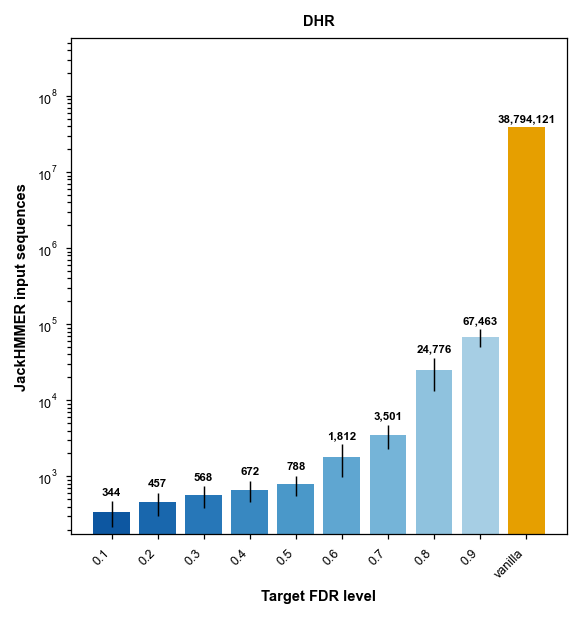

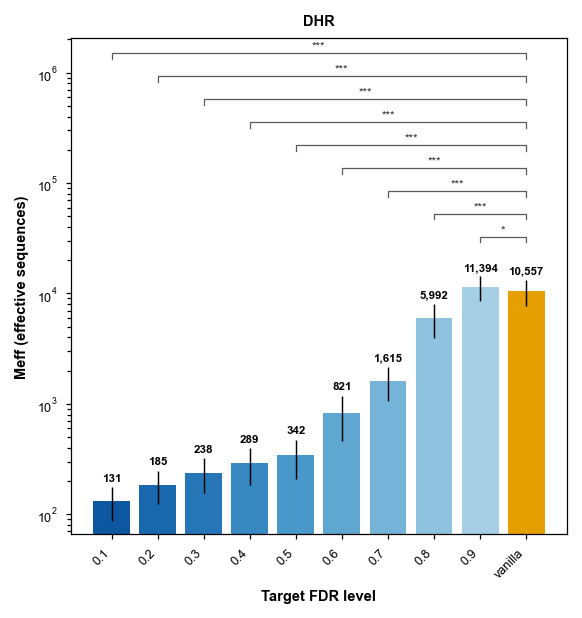

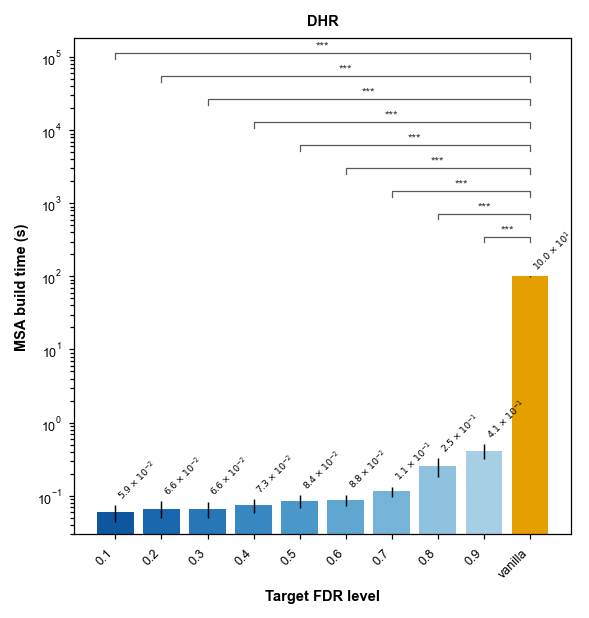

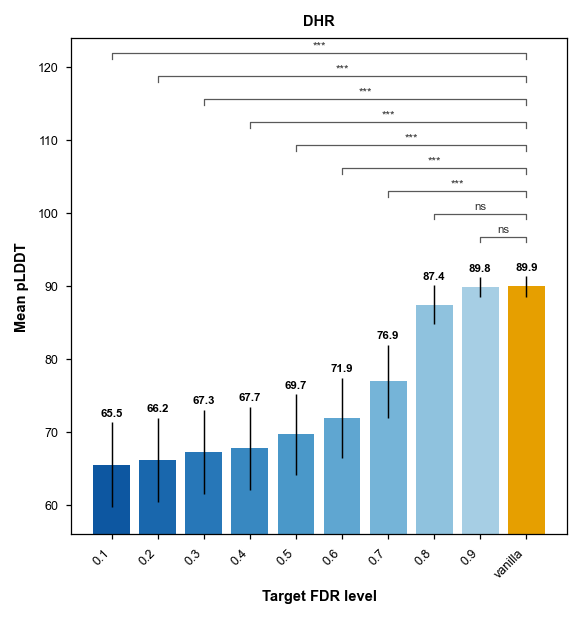

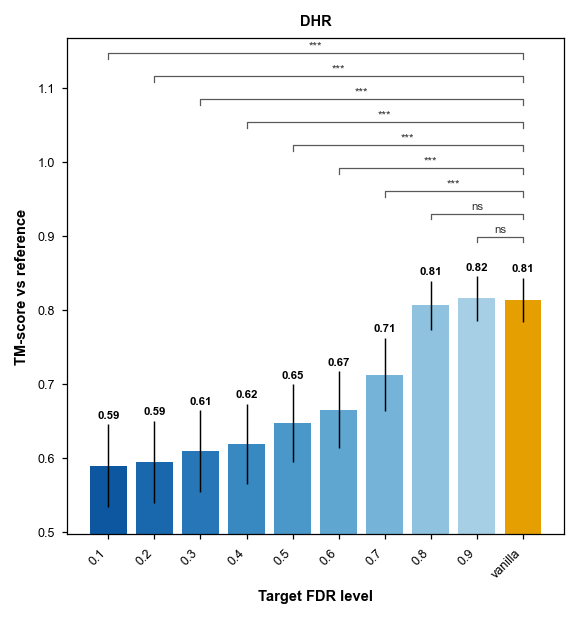

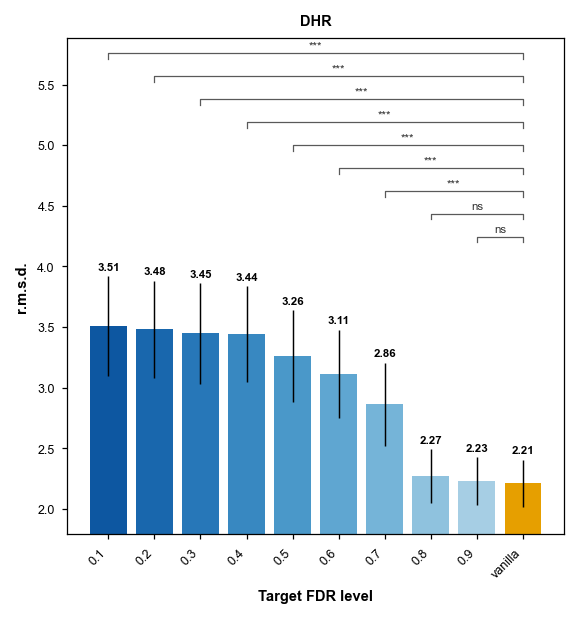

[OK] /home/yfnyang/2025_PLMCaliper_All/PLMCaliper/results/ColabFold/paired_ttest.tsv: 48/54 (metric, q) cells significant after Holm


In [ ]:
def barplot_metric(df, metric, searching_method, stats):
    score_method = search2score_mapping[searching_method]
    # mean and 95% CI over queries of each FDR arm, then of the baseline
    tags = [EFDR_TAG[q] for q in Q_LEVELS] + [BASELINE]
    g = df.groupby("tag")[metric]
    means = g.mean().reindex(tags).to_numpy(float, copy=True)
    cis = (1.96 * g.std() / np.sqrt(g.count())).reindex(tags).fillna(0.0).to_numpy(float, copy=True)
    if metric == "n_hits": # the baseline searches the whole database
        means[-1], cis[-1] = FULL_DB_SIZE, 0.0
    if not np.isfinite(means).any():
        print(f"[skip] {metric}: no data")
        return
    x, log, brackets = np.arange(len(means)), metric in LOGY, metric != "n_hits"

    fig, ax = plt.subplots(figsize=(4.8, 4.3))
    ax.set_box_aspect(1)
    if log:
        ax.set_yscale("log")
    colors = [EFDR_CMAP(0.85 - 0.5 * i / (len(Q_LEVELS) - 1)) for i in range(len(Q_LEVELS))] + [VAN_COLOR]
    ax.bar(x, means, width=0.8, color=colors, edgecolor="none", zorder=2)
    lo, hi = means - cis, means + cis
    if log:
        lo = np.clip(lo, np.nanmin(means[means > 0]) * 0.5, None)
    ax.errorbar(x, means, yerr=np.clip(np.nan_to_num(np.vstack([means - lo, hi - means])), 0.0, None),
                fmt="none", ecolor="black", elinewidth=0.7, capsize=0, zorder=4)

    top_frac = 0.52 if brackets else 0.82
    if log:
        bottom = np.nanmin(means[means > 0]) * 0.5
        ax.set_ylim(bottom, bottom * (np.nanmax(hi) / bottom) ** (1.0 / top_frac))
    else:
        span = max(np.nanmax(hi) - np.nanmin(lo), 1e-9)
        bottom = np.nanmin(lo) - 0.12 * span
        bottom = max(0.0, bottom) if np.nanmin(lo) >= 0 else bottom
        ax.set_ylim(bottom, bottom + (np.nanmax(hi) - bottom) / top_frac)

    rot = 45 if metric == "msa_seconds" else 0
    for xi, m, h in zip(x, means, hi):
        if not np.isfinite(m):
            continue
        if metric == "msa_seconds":
            e = int(np.floor(np.log10(m))) if m > 0 else 0
            label = rf"${m / 10 ** e:.1f}\times10^{{{e}}}$"
        else:
            label = VALUE_FMT.get(metric, "{:.2f}").format(m)
        ax.annotate(label, (xi, h), textcoords="offset points", xytext=(0, 2), ha="left" if rot else "center",
                    va="bottom", rotation=rot, fontsize=4.5 if rot else 5.5, fontweight="bold")

    if brackets:
        stars = stats.set_index(["metric", "q"])["stars"]
        trans = ax.get_xaxis_transform()
        for k, i in enumerate(reversed(range(len(Q_LEVELS)))):
            if not np.isfinite(means[i]):
                continue
            y = 0.60 + k * (0.97 - 0.60) / (len(Q_LEVELS) - 1)
            ax.plot([x[i], x[i], x[-1], x[-1]], [y - 0.012, y, y, y - 0.012], transform=trans, color="0.35", lw=0.6, clip_on=False)
            ax.text((x[i] + x[-1]) / 2, y + 0.004, stars[(metric, Q_LEVELS[i])], transform=trans,
                    ha="center", va="bottom", fontsize=5.5, color="0.2", clip_on=False)

    ax.set_xticks(x, [f"{q:.1f}" for q in Q_LEVELS] + ["vanilla"], rotation=45, ha="right")
    ax.set_xlabel("Target FDR level", fontweight="bold")
    ax.set_ylabel(LABELS[metric], fontweight="bold")
    ax.set_title(METHOD_LABEL[searching_method], fontweight="bold")
    # os.makedirs(f"{FIG_DIR}/{score_method}", exist_ok=True)
    # fig.savefig(f"{FIG_DIR}/{score_method}/bar_{metric}.pdf", bbox_inches="tight")
    plt.show()

searching_method = "dhr" # or "plm", "tmvec"
df = pd.read_csv(f"{OUT_DIR}/{search2score_mapping[searching_method]}_iter1_metrics.tsv", sep="\t") # your own run: f"{OUT_DIR}/{search2score_mapping[searching_method]}/iter1/metrics.tsv"
df = df[df["af2_status"].isin(["ok", "reused"])]
stats = stats_table(df)
for metric in METRICS:
    barplot_metric(df, metric, searching_method, stats)

stats.to_csv(f"{FIG_DIR}/paired_ttest.tsv", sep="\t", index=False)
print(f"[OK] {FIG_DIR}/paired_ttest.tsv: {int((stats['p_holm'] < 0.05).sum())}/{len(stats)} (metric, q) cells significant after Holm")